*Notebook 01 of 12 in `notebooks/scripts_text/`. Parameters: `analysis/scripts_text/config.yaml`; decisions and run notes: `analysis/scripts_text/LOG.md`. The static page `site/scripts/index.html` is built from the same outputs.*

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve().parents[1]   # notebooks/scripts_text -> repo root
sys.path.insert(0, str(REPO))

import warnings

import pandas as pd
import plotly.io as pio
from IPython.display import Markdown, display

from analysis.scripts_text.report import nb_md
from analysis.static_figures import use_static_figures

from analysis.scripts_text import s01_groups as step

use_static_figures()   # figures become static PNGs (they show on GitHub); interactive ones are on the static page
warnings.filterwarnings("ignore", category=RuntimeWarning)   # known 0/0 on very short arcs, handled downstream
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

## Step 1 · Who counts as a success?

This step asks which films count as successful and which as unsuccessful, so that every later step has two
groups to compare.

### What we do

We measure success as a film's gross divided by its budget. When we need a number on a continuous scale we use
log(gross/budget): 0 means the film grossed exactly its budget, and 1 means it grossed about 2.7 times its
budget. From that we build three pairs of groups for the 1,095 clean 100k+ films that have a usable MovieSum
script:

- (A) Unprofitable films (gross below budget) against everyone else. It's the most literal definition, but the
  unprofitable group is tiny.
- (B) The bottom quarter against the top quarter of log(gross/budget). We compute the cut-offs on all 2,446
  clean films, with or without a script, so a film's label doesn't depend on which other films happen to have
  one.
- (C) The same quarters, but cut separately inside each primary-genre × decade cell (all the films that share
  one primary genre and one decade). A horror film from the 2000s is then compared with other horror films
  from the 2000s, not with dramas from the 1970s.

### Why

Scattertext compares two groups, so we have to say which two. The course's "compared to what?" question starts
here, because a word can only be distinctive of success relative to some definition of failure.

### What it measures

How much a film earned relative to what it cost to make, as reported in its Wikipedia infobox.

### What it misses

Gross minus budget isn't profit. Marketing isn't in the budget, cinemas keep a large share of the gross (often
around half), and nothing is adjusted for inflation. The ratio is unaffected by inflation only because budget
and gross are in the same year's dollars. It also rewards very cheap films: a \$1 million horror film that
grosses \$50 million beats a \$200 million blockbuster that grosses \$1 billion.

### Primary analysis, fixed in advance

Definition (C), the dialogue layer, character names removed and a minimum document frequency of 5. Everything
else in these notebooks is exploratory.

> **Takeaway.** Our main definition (C) compares the bottom and top quarter of films by gross/budget within the same genre and decade. Budgets still differ inside those cells (median \$40.0M for the unsuccessful group against \$25.0M for the successful one, p = 0.0065), which is why Step 4 also matches on budget.

In [2]:
res = step.run()   # recomputes this step and saves its outputs

**Table.** Before computing anything else, we check that the coverage numbers reproduce.

In [3]:
display(step.tables(res)["checks"])

,check,got,expected,match
0,clean_movies,2446,2446,True
1,clean_with_usable_script,1095,1095,True
2,gross_below_budget,67,67,True
3,global_quartile_bottom,243,243,True
4,global_quartile_top,306,306,True


**Table.** How many scripts land in each group under each definition. All films are in the 100k+ vote tier.

In [4]:
display(step.tables(res)["sizes"])

,definition,meaning,tier,low (unsuccessful),high (successful),not in either group
0,A,unprofitable (gross < budget) vs all others,100k+,67,1028,0
1,B,"bottom vs top quartile of log(gross/budget), all films",100k+,243,306,546
2,C,bottom vs top quartile within genre × decade cells,100k+,237,292,566


**Figure.** log(gross/budget) for the 2,446 clean films, split by whether MovieSum has their script. The dashed lines mark the quartile cuts used for (B) and break-even. Scripted films sit further right, so the script sample over-represents hits. That's why (B) has 306 successful scripts but only 243 unsuccessful ones.

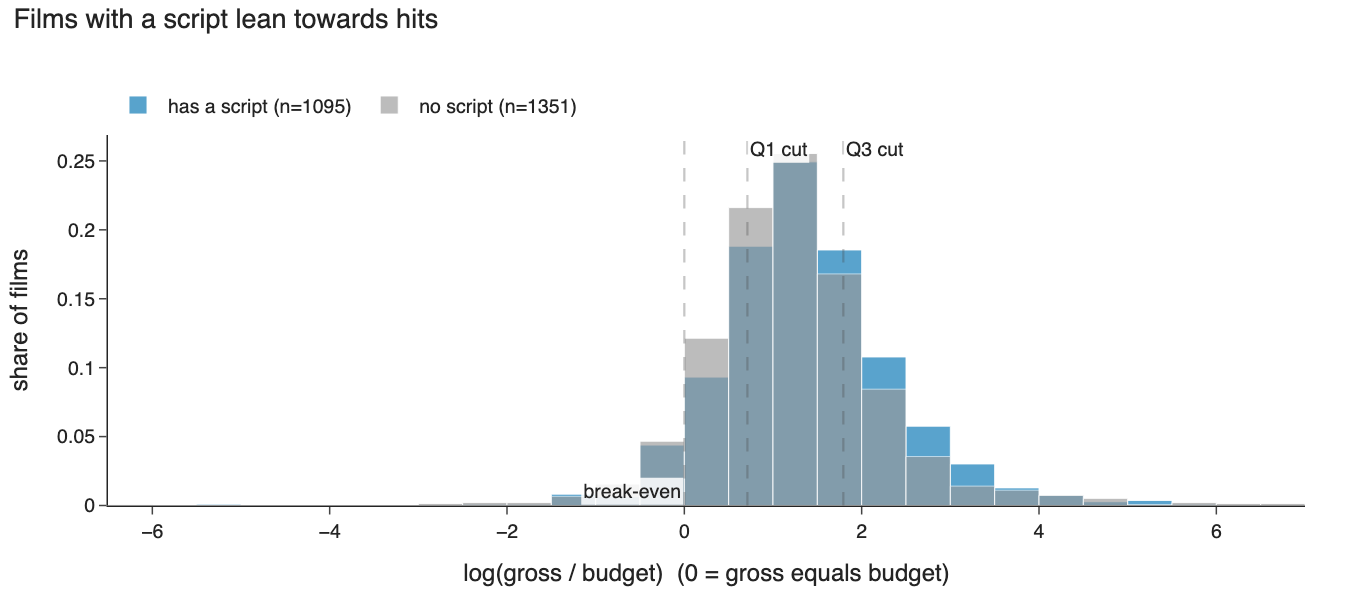

In [5]:
step.figures(res)["coverage"].show()

**Figure.** Budgets of the unsuccessful (orange) and successful (blue) scripts under each definition, on a log scale. Check whether the two boxes overlap. Where they don't, a word difference between the groups could really be a budget difference.

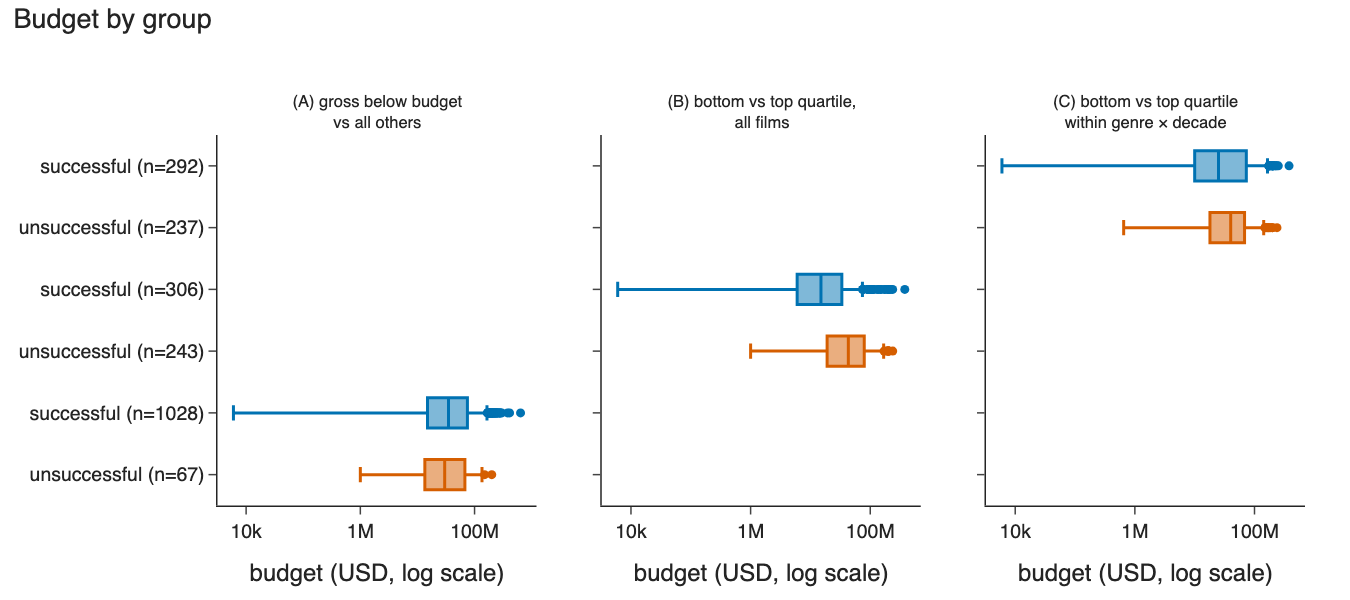

In [6]:
step.figures(res)["budget"].show()

**Figure.** Release year by group. If the boxes are shifted, era could explain word differences, since language changes over the decades.

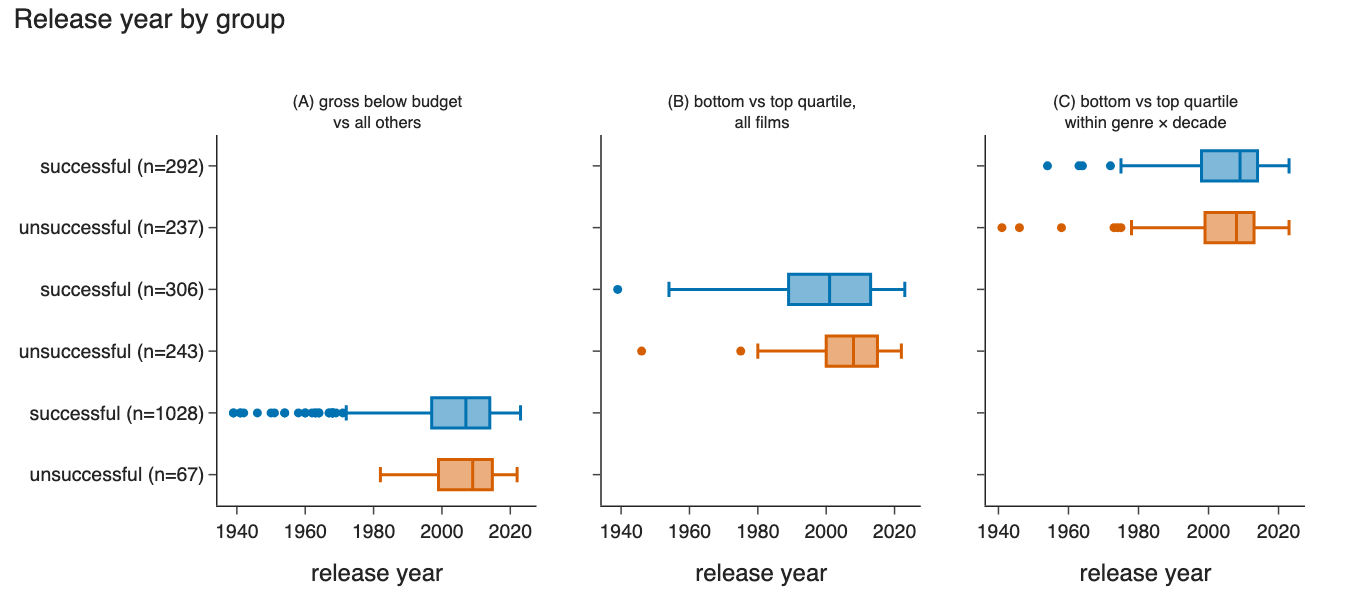

In [7]:
step.figures(res)["year"].show()

**Figure.** Share of each primary genre in each group. Every genre also has its own fill pattern, so the chart reads without colour. Horror's share among successful films under (A) and (B) is the known micro-budget bias. (C) equalises genre by construction.

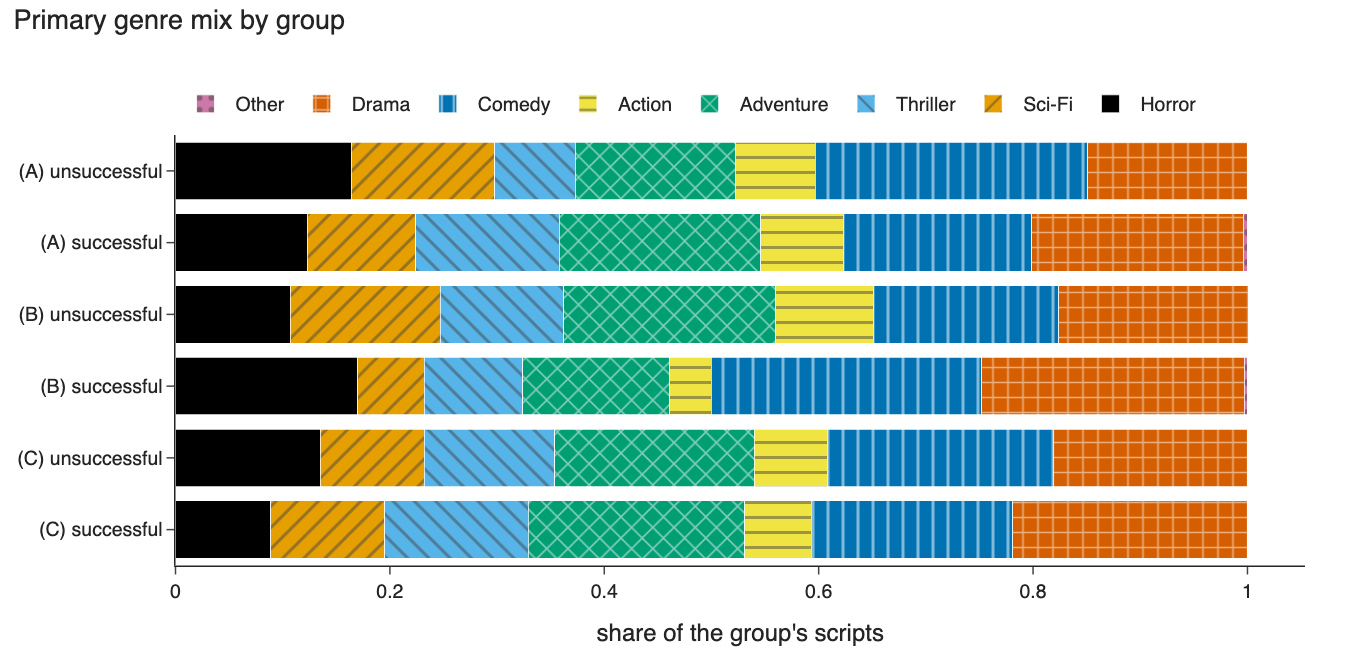

In [8]:
step.figures(res)["genre_mix"].show()

**Table.** The budget-bias test: median budget, median year and horror share in each group, plus a Mann-Whitney test of log budget between the two groups (a rank test of whether one group's budgets tend to be higher than the other's).

In [9]:
display(step.tables(res)["bias"])

,definition,"median budget, low ($M)","median budget, high ($M)","median year, low","median year, high","horror share, low","horror share, high","Mann-Whitney p, log budget"
0,A,30.0,35.0,2009,2007,0.164,0.123,3.300000e-01
1,B,43.0,15.0,2008,2001,0.107,0.170,5.100000e-20
2,C,40.0,25.0,2008,2009,0.135,0.089,6.500000e-03


**Table.** Definition (C) within a single genre or a single decade. We only use a stratum if both groups have at least 30 scripts (the brief's rule).

In [10]:
display(step.tables(res)["strata"])

,stratum,value,scripts,low,high,usable
0,genre,Action,84,14,20,no: a group has fewer than 30
1,genre,Adventure,203,40,57,yes
2,genre,Comedy,198,56,57,yes
3,genre,Drama,213,44,68,yes
4,genre,Horror,137,37,37,yes
5,genre,Other,4,2,0,no: a group has fewer than 30
6,genre,Sci-Fi,113,23,36,no: a group has fewer than 30
7,genre,Thriller,143,29,37,no: a group has fewer than 30
8,decade,1980s,78,16,26,no: a group has fewer than 30
9,decade,1990s,203,49,60,yes


**Table.** Genre × decade cells. A cell needs at least 20 clean films, scripted or not, before we can cut quartiles. Scripts in smaller cells are left out of (C) and counted here.

In [11]:
display(step.tables(res)["cells"])

,cell,scripts,cell_ok,low,high
9,Adventure | 2010s,87,True,19,25
21,Drama | 2010s,76,True,15,23
15,Comedy | 2010s,69,True,17,22
14,Comedy | 2000s,53,True,18,16
8,Adventure | 2000s,50,True,7,16
20,Drama | 2000s,49,True,11,10
41,Thriller | 2000s,49,True,9,13
27,Horror | 2010s,47,True,13,15
36,Sci-Fi | 2010s,45,True,10,15
19,Drama | 1990s,43,True,10,17


**Plain-language reading** (generated from the saved numbers):

In [12]:
display(Markdown(nb_md(step.reading(res))))

All five coverage checks reproduce (clean_movies 2,446, clean_with_usable_script 1,095, gross_below_budget 67, global_quartile_bottom 243, global_quartile_top 306). Under (A) only 67 scripts are unsuccessful, so any word-level test on (A) has little power. Under (B) the bottom quartile's median budget is \$43.0M against \$15.0M for the top quartile (Mann-Whitney p = 5.1e-20), and horror makes up 17% of the top quartile but only 11% of the bottom. Within genre × decade cells (C), the unsuccessful group's median budget is \$40.0M against \$25.0M for the successful group (p = 0.0065). So (C) removes the genre and era difference but not all of the budget difference, and Step 4's matching takes care of budget. 32 of the 47 genre × decade cells have at least 20 clean films. 76 scripts sit in cells too small to cut quartiles, so they're left out of (C). 7 single-genre or single-decade strata are skipped because one of their groups has fewer than 30 scripts: Action, Other, Sci-Fi, Thriller, 1980s, 2020s, pre-1980. Our priority rule for choosing a film's primary genre agrees with Àngela's first-listed rule for 49% of scripts.

### Why we keep three definitions for now

(A) is the most literal reading of "unprofitable", but it has so few scripts that rare words can't be tested.
(B) is larger and more robust, but it mixes genres and eras, so it partly measures "horror vs drama" or "1980s
vs 2010s". (C) controls genre and era by construction, which is why it's the primary analysis. None of the
three fully controls budget. Step 4 does that by matching.